# 02 · NLP de tickets: sarcasmo, intención y validación — Conecta+

**Problema (P15):** muchos clientes se quejan con palabras positivas
(por ejemplo, "agradecen" el servicio mientras reclaman un cobro doble repetido). Un análisis de sentimiento
ingenuo los lee como satisfechos.

**Enfoque elegido:** reglas transparentes sobre léxicos genéricos (`conecta/nlp.py`), integradas en
`silver/tickets` con columnas `nlp_*`. Se validan contra cuatro referencias:

| Validación | Qué mide |
|---|---|
| Set de referencia (38 textos únicos reales, etiquetados a mano) | Precisión sobre los datos de la prueba |
| Set de desarrollo (30 frases nuevas) | Se usó para corregir reglas → ya no es independiente |
| Set de prueba (24 frases nuevas, nunca usadas para ajustar) | Generalización honesta a textos nuevos |
| Modelo externo pysentimiento (RoBERTuito, ironía + sentimiento) | Contraste con un modelo preentrenado independiente |
| Relación con churn real | Si las señales sirven para el negocio |

Las etiquetas de referencia se guardan por huella del texto (`conecta/recursos/referencia_nlp.csv`),
sin el texto, para no subir datos al repositorio.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from conecta import io, nlp, nlp_validacion as v
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 220)
AZUL, NARANJA, TINTA, TENUE = "#2a78d6", "#eb6834", "#2b2b2b", "#8a8a86"
plt.rcParams.update({"figure.figsize": (9, 3.4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": TENUE, "axes.grid": True, "grid.color": "#e6e6e3", "axes.axisbelow": True,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "xtick.color": TENUE, "ytick.color": TENUE,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
LAKE = RAIZ / "lake"
tk = io.read(LAKE, "silver", "tickets")
print(f"{len(tk)} tickets · {tk.texto_cliente.nunique()} textos de cliente distintos · "
      f"{tk.respuesta_agente.nunique()} respuestas de agente distintas (genéricas, sin señal)")

4678 tickets · 38 textos de cliente distintos · 3 respuestas de agente distintas (genéricas, sin señal)


## 1. Los 38 textos reales: etiqueta manual vs reglas
Revisar esta tabla es la forma más directa de auditar el NLP (columna `ok`). Por confidencialidad se muestra la
huella del texto (`clave_texto`); la revisión con el texto completo se hizo en local.

In [2]:
ref = v.referencia(LAKE)
ref["ok"] = np.where((ref.sarcasmo == ref.pred_sarcasmo) & (ref.intencion == ref.pred_intencion), "✓", "✗")
# Confidencialidad: se muestra la huella del texto (clave_texto), no el texto del cliente.
# Para auditar localmente con el texto: ref[["clave_texto", "texto_cliente", ...]]
ref.sort_values(["sarcasmo", "categoria"], ascending=[False, True])[
    ["categoria", "clave_texto", "n_tickets", "sarcasmo", "pred_sarcasmo", "intencion", "pred_intencion",
     "sentimiento", "pred_sentimiento", "pred_sentimiento_lexico", "ok"]]

,categoria,clave_texto,n_tickets,sarcasmo,pred_sarcasmo,intencion,pred_intencion,sentimiento,pred_sentimiento,pred_sentimiento_lexico,ok
2,app_se_cierra,66d806ca1dd1f43b,164,1,1,soporte,soporte,negativo,negativo,positivo,✓
5,app_se_cierra,a8cae67cad747d9a,195,1,1,soporte,soporte,negativo,negativo,positivo,✓
7,cambio_clave,b061ff719931a9b7,104,1,1,soporte,soporte,negativo,negativo,positivo,✓
16,cancelar,373bd8a29fec96f3,104,1,1,cancelar,cancelar,negativo,negativo,positivo,✓
22,cobro_doble,bc658e3ecfc61ad0,67,1,1,soporte,soporte,negativo,negativo,positivo,✓
25,cobro_doble,90fa369c1ba5c22f,67,1,1,soporte,soporte,negativo,negativo,positivo,✓
27,cobro_doble,cb12540dd50f69bb,70,1,1,soporte,soporte,negativo,negativo,positivo,✓
31,lentitud,972087f2603839a4,149,1,1,soporte,soporte,negativo,negativo,positivo,✓
36,no_reconoce_cobro,fec0c217366c577d,54,1,1,soporte,soporte,negativo,negativo,positivo,✓
0,app_se_cierra,759732c57ab8f369,85,0,0,soporte,soporte,negativo,negativo,negativo,✓


In [3]:
print("Métricas sobre los 38 textos únicos:"); display(v.metricas(ref, v.CAMPOS))
print("Ponderado por número de tickets:"); display(v.metricas(ref, v.CAMPOS, "n_tickets"))
s = ref[ref.sarcasmo == 1]
print(f"Léxico ingenuo en los {len(s)} textos sarcásticos: los lee como positivos el "
      f"{(s.pred_sentimiento_lexico == 'positivo').mean():.0%} → sentimiento correcto {v.linea_base_ingenua(ref):.0%}")

Métricas sobre los 38 textos únicos:


,campo,exactitud,f1_macro,n
0,sarcasmo,1.000,1.000,38
1,sentimiento,0.895,0.864,38
2,intencion,1.000,1.000,38
3,frustracion,0.947,0.956,38
4,recurrente,1.000,1.000,38
5,tema_precio,1.000,1.000,38


Ponderado por número de tickets:


,campo,exactitud,f1_macro,n
0,sarcasmo,1.000,1.000,38
1,sentimiento,0.882,0.855,38
2,intencion,1.000,1.000,38
3,frustracion,0.959,0.962,38
4,recurrente,1.000,1.000,38
5,tema_precio,1.000,1.000,38


Léxico ingenuo en los 9 textos sarcásticos: los lee como positivos el 100% → sentimiento correcto 0%


Desacuerdos que quedan (sentimiento y frustración) son casos ambiguos: reportes corteses de un problema
(un cobro duplicado pedido con amabilidad) que pueden leerse como neutros o negativos.
Para churn importan más la **intención** y el **sarcasmo**, que están al 100 %.

## 2. Generalización: desarrollo vs prueba (frases nuevas)

In [4]:
dev = v.robustez()
te = pd.read_csv(RAIZ / "conecta/recursos/prueba_nlp.csv")
te = te.join(pd.DataFrame([nlp.analizar(x) for x in te.texto]).add_prefix("pred_"))
comp = pd.concat([v.metricas(dev, ["sarcasmo", "sentimiento", "intencion"]).assign(set="desarrollo (usado para ajustar)"),
                  v.metricas(te, ["sarcasmo", "sentimiento", "intencion"]).assign(set="prueba (nunca vista)")])
display(comp.pivot(index="campo", columns="set", values=["exactitud", "f1_macro"]))
print("Errores en el set de prueba:")
for c in ["sarcasmo", "sentimiento", "intencion"]:
    for r in te[te[c].astype(str) != te["pred_" + c].astype(str)].itertuples():
        print(f"  {c:12} esperado={getattr(r, c):9} regla={getattr(r, 'pred_' + c):9} | {r.texto}")

exactitud                                             f1_macro                     
set         desarrollo (usado para ajustar) prueba (nunca vista) desarrollo (usado para ajustar) prueba (nunca vista)
campo                                                                                                                
intencion                               1.0                0.958                             1.0                0.744
sarcasmo                                1.0                0.792                             1.0                0.705
sentimiento                             1.0                0.792                             1.0                0.807

Errores en el set de prueba:
  sarcasmo     esperado=        1 regla=        0 | Felicidades, lograron que la app sea más lenta que antes.
  sarcasmo     esperado=        1 regla=        0 | Qué gran servicio, cuatro días sin poder ver nada.
  sarcasmo     esperado=        1 regla=        0 | Increíble cómo me cobran el doble y nadie responde. Bravo.
  sarcasmo     esperado=        0 regla=        1 | Excelente servicio, nunca he tenido problemas.
  sarcasmo     esperado=        1 regla=        0 | Muy chévere que me cobren la reconexión sin haberme desconectado.
  sentimiento  esperado=positivo  regla=negativo  | Excelente servicio, nunca he tenido problemas.
  sentimiento  esperado=negativo  regla=neutro    | Esto es un abuso, tres meses con el mismo problema.
  sentimiento  esperado=negativo  regla=neutro    | Si siguen subiendo el precio me voy a la competencia.
  sentimiento  esperado=negativo  regla=neutro    | Quiero un plan más económico, el actual no lo alcanzo a pagar.
  sent

**Lectura honesta:** sobre los datos de la prueba las reglas son exactas, pero con textos nuevos el sarcasmo
baja a ~79 % de exactitud. Fallan elogios no listados ("felicidades", "qué gran servicio", "chévere")
y negaciones de problemas ("nunca he tenido problemas"). En producción habría que ampliar el léxico
con tickets nuevos etiquetados y monitorear la tasa de textos fuera del set de referencia (check P15).

## 3. Contraste con un modelo preentrenado (pysentimiento)

In [5]:
archivos = {n: LAKE / "_calidad" / f"nlp_ext_{n}.parquet" for n in ["referencia_38", "desarrollo_30", "prueba_24"]}
if all(p.exists() for p in archivos.values()):
    ext = {n: pd.read_parquet(p) for n, p in archivos.items()}
else:   # recalcular (requiere pip install pysentimiento; descarga ~1 GB de modelos)
    base = {"referencia_38": ref.rename(columns={"texto_cliente": "texto"}), "desarrollo_30": dev, "prueba_24": te}
    ext = {}
    for n, d in base.items():
        e = v.modelo_externo(d.texto)
        if e is None:
            raise SystemExit("pysentimiento no instalado: se omite esta sección")
        ext[n] = d.reset_index(drop=True).join(e)
from sklearn.metrics import f1_score
filas = []
for n, d in ext.items():
    filas += [{"set": n, "tarea": "sarcasmo", "reglas": f1_score(d.sarcasmo, d.pred_sarcasmo),
               "pysentimiento": f1_score(d.sarcasmo, d.ext_ironia)},
              {"set": n, "tarea": "sentimiento (F1 macro)", "reglas": f1_score(d.sentimiento, d.pred_sentimiento, average="macro"),
               "pysentimiento": f1_score(d.sentimiento, d.ext_sentimiento, average="macro")}]
display(pd.DataFrame(filas).round(3))
r38 = ext["referencia_38"]; s = r38[r38.sarcasmo == 1]
print(f"En los {len(s)} textos sarcásticos reales, pysentimiento: ironía detectada en {s.ext_ironia.sum()}, "
      f"sentimiento 'positivo' en {(s.ext_sentimiento == 'positivo').sum()}")
display(s.assign(clave_texto=s.texto.map(nlp.clave_texto))[["clave_texto", "ext_p_ironia", "ext_sentimiento"]].round(2))  # sin textos

,set,tarea,reglas,pysentimiento
0,referencia_38,sarcasmo,1.000,0.714
1,referencia_38,sentimiento (F1 macro),0.864,0.431
2,desarrollo_30,sarcasmo,1.000,0.615
3,desarrollo_30,sentimiento (F1 macro),1.000,0.770
4,prueba_24,sarcasmo,0.545,0.429
5,prueba_24,sentimiento (F1 macro),0.807,0.749


En los 9 textos sarcásticos reales, pysentimiento: ironía detectada en 5, sentimiento 'positivo' en 7


,clave_texto,ext_p_ironia,ext_sentimiento
2,66d806ca1dd1f43b,0.48,positivo
5,a8cae67cad747d9a,1.00,positivo
7,b061ff719931a9b7,0.18,negativo
16,373bd8a29fec96f3,0.11,positivo
22,bc658e3ecfc61ad0,0.96,positivo
25,90fa369c1ba5c22f,0.99,positivo
27,cb12540dd50f69bb,1.00,positivo
31,972087f2603839a4,0.33,neutro
36,fec0c217366c577d,0.99,positivo


El modelo preentrenado **confirma que el sarcasmo es real** (detecta ironía con alta probabilidad en varios)
pero se equivoca más que las reglas en los tres sets y clasifica casi todas las quejas sarcásticas como
"positivas". Por eso las reglas van a silver y pysentimiento queda solo como validación externa (opcional, pesado).

## 4. ¿Las señales NLP se relacionan con el churn?
Tickets con ventana observable de 90 días (creados hasta 2025-10-02); churn = el cliente se va en los 90 días siguientes al ticket.

In [6]:
su = io.read(LAKE, "silver", "suscripciones")
fin = su[su.fin_es_churn].groupby("cliente_id").fecha_fin.max()
t = tk.merge(fin.rename("fecha_churn").reset_index(), on="cliente_id", how="left")
t = t[t.creado_en <= pd.Timestamp("2025-12-31") - pd.Timedelta(days=90)]
d = (t.fecha_churn - t.creado_en.dt.normalize()).dt.days
t["churn_post"] = ((d >= 0) & (d <= 90)).astype(int)
print(f"Tickets evaluables: {len(t)} · tasa base de churn: {t.churn_post.mean():.1%}")
for col in ["nlp_intencion", "nlp_frustracion", "nlp_sentimiento", "nlp_sentimiento_lexico"]:
    display(t.groupby(col).churn_post.agg(tickets="size", tasa_churn="mean").round(3))

Tickets evaluables: 3470 · tasa base de churn: 30.5%


,tickets,tasa_churn
nlp_intencion,,
amenaza_irse,169,0.213
bajar_plan,154,0.084
cancelar,572,1.000
soporte,2502,0.171
subir_plan,73,0.096


,tickets,tasa_churn
nlp_frustracion,,
0,1646,0.301
1,1023,0.239
2,801,0.395


,tickets,tasa_churn
nlp_sentimiento,,
negativo,2607,0.264
neutro,863,0.426


,tickets,tasa_churn
nlp_sentimiento_lexico,,
negativo,2255,0.344
neutro,569,0.130
positivo,646,0.322


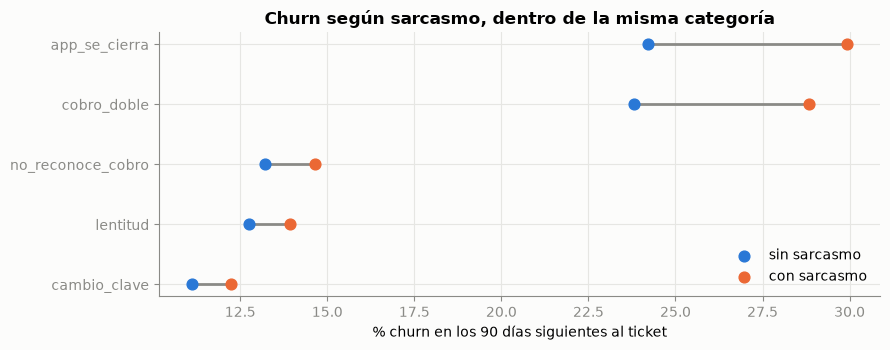

In [7]:
x = t[t.categoria != "cancelar"].groupby(["categoria", "nlp_sarcasmo"]).churn_post.mean().unstack()
x = x.dropna().sort_values(1)
fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(x))
ax.hlines(y, x[0] * 100, x[1] * 100, color=TENUE, linewidth=2)
ax.scatter(x[0] * 100, y, color=AZUL, s=60, zorder=3, label="sin sarcasmo")
ax.scatter(x[1] * 100, y, color=NARANJA, s=60, zorder=3, label="con sarcasmo")
ax.set_yticks(y, x.index); ax.set_xlabel("% churn en los 90 días siguientes al ticket")
ax.set_title("Churn según sarcasmo, dentro de la misma categoría"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

**Conclusiones para el modelo**
- La **intención** es la señal más fuerte: pedir cancelar → 100 % de churn (llega 1–14 días antes);
  amenaza de irse 21 %; pedir bajar de plan solo 8 % (oportunidad de retención, no de pérdida).
- **Frustración alta** (2) → ~40 % vs 30 % base.
- El **sarcasmo** suma una señal pequeña pero consistente dentro de cada categoría (hasta +6 pp en
  `app_se_cierra` y `cobro_doble`). Su mayor valor es evitar leer como satisfechos a clientes molestos.
- El **sentimiento solo engaña**: "neutro" tiene más churn porque las solicitudes corteses de cancelación son neutras.
  Debe usarse junto con la intención.
- El efecto final de cada señal se medirá en el modelo (importancia de variables y ablación).

## 5. Anotación: ¿cortes de entrenamiento adicionales mejoran el modelo?

In [8]:
p = LAKE / "_calidad" / "experimento_cortes.csv"
if not p.exists():
    from conecta import experimento_cortes as ec
    res, deltas, _ = ec.run(LAKE)
    res.to_csv(p, index=False); deltas.to_csv(LAKE / "_calidad" / "experimento_cortes_deltas.csv", index=False)
display(pd.read_csv(p).round(4))
display(pd.read_csv(LAKE / "_calidad" / "experimento_cortes_deltas.csv").round(4))

,variante,modelo,n_cortes,filas_train,tasa_churn_train,roc_auc,pr_auc,brier,log_loss
0,A_oficiales_mar_jun,logistica,2,3067,0.1216,0.7333,0.4073,0.1199,0.3916
1,A_oficiales_mar_jun,lightgbm,2,3067,0.1216,0.7131,0.3597,0.1207,0.4006
2,B_mensual_2025,logistica,6,8805,0.1118,0.7374,0.4127,0.1180,0.3866
3,B_mensual_2025,lightgbm,6,8805,0.1118,0.7224,0.3966,0.1172,0.3897
4,C_mensual_desde_2024,logistica,18,19287,0.1048,0.7214,0.3673,0.1395,0.4390
5,C_mensual_desde_2024,lightgbm,18,19287,0.1048,0.6958,0.3692,0.1202,0.4016
6,D_mensual_desde_2023,logistica,24,21344,0.1038,0.7186,0.3624,0.1426,0.4478
7,D_mensual_desde_2023,lightgbm,24,21344,0.1038,0.6990,0.3720,0.1199,0.3993


,variante,modelo,delta_auc_vs_A,ic95_bajo,ic95_alto
0,B_mensual_2025,logistica,0.0042,-0.0007,0.0089
1,B_mensual_2025,lightgbm,0.0096,-0.0068,0.0255
2,C_mensual_desde_2024,logistica,-0.0115,-0.0262,0.0041
3,C_mensual_desde_2024,lightgbm,-0.0172,-0.0423,0.0087
4,D_mensual_desde_2023,logistica,-0.0144,-0.0290,0.0016
5,D_mensual_desde_2023,lightgbm,-0.0139,-0.0374,0.0115


Prueba fuera de tiempo en el corte oficial 2025-09-30, con features provisionales al corte
(`conecta/experimento_cortes.py`). **Conclusión: no es relevante.** Los cortes mensuales de 2025 mejoran el AUC
apenas (+0,004 a +0,010) con un IC 95 % que incluye 0; agregar 2023–2024 **empeora** AUC y calibración, porque esos
meses no tienen logs de la app y son otro régimen (precio anterior del Básico, app sin el fallo de la versión 5.4.0).
Se mantienen los 3 cortes oficiales; se puede reconsiderar la variante B como análisis de sensibilidad.